# YOLO Object Detection

YOLOv5 모델을 사용한 객체 검출

## 1. 개요 및 시스템 구조

### YOLO (You Only Look Once) 기본 개념
YOLO는 객체 검출을 위한 딥러닝 모델로, 하나의 신경망으로 전체 이미지를 한 번에 처리하여 여러 물체의 위치와 클래스를 동시에 예측합니다.

[Yolo V5 Concept](https://drive.google.com/file/d/1fr7a2Q5WwX-WjrThTkog-oaW-o1UKFdZ/view?usp=drive_link)


### 전체 처리 파이프라인
1. **이미지 입력**: 원본 이미지 로드
2. **전처리**: 크기 조정, 패딩, 색상 변환
3. **NPU 추론**: DX Runtime을 통한 모델 실행
4. **후처리**: 결과 디코딩, NMS 적용, 좌표 변환
5. **결과 시각화**: 검출 결과 그리기 및 저장

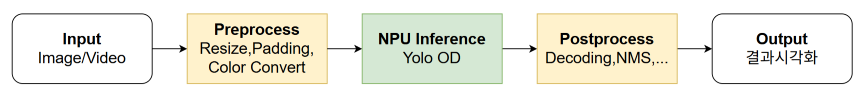

## 2. 모델 설명: YOLOV5S-1.dxnn

### 모델 정보
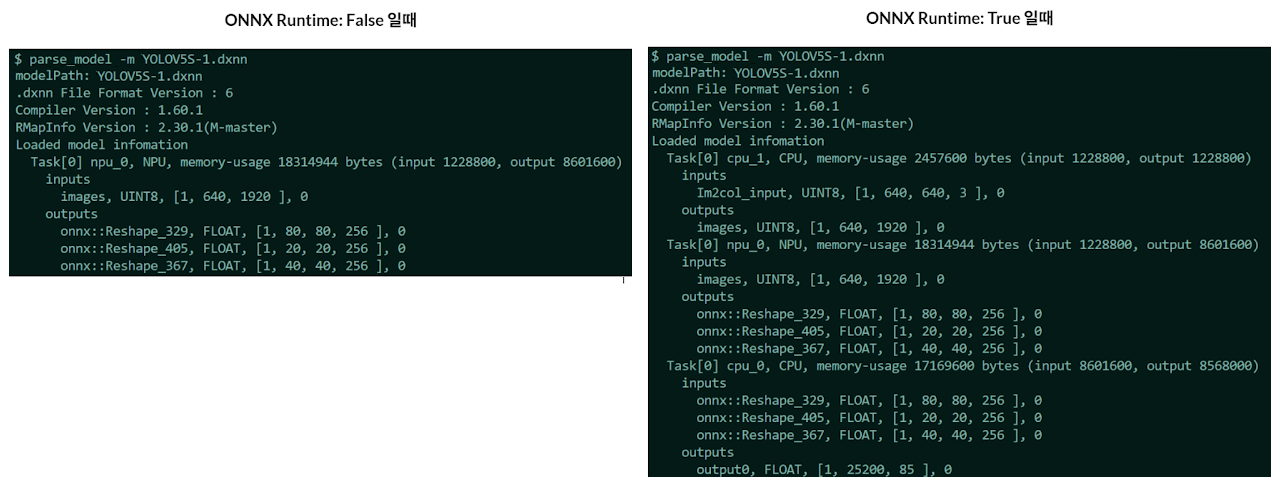

### 입력/출력 텐서 구조
- **입력 텐서**: `images` - UINT8, [1, 640, 640, 3]
- **출력 텐서**: `output0` - FLOAT, [1, 25200, 85]

### NPU/CPU Task 구조
#### Task[0] cpu_1
- **출력**: [1, 640, 1920]

#### Task[0] npu_0
- **출력**:
  - `onnx::Reshape_405`: [1, 255, 20, 20] (20x20 그리드)
  - `onnx::Reshape_329`: [1, 255, 80, 80] (80x80 그리드)  
  - `onnx::Reshape_367`: [1, 255, 40, 40] (40x40 그리드)

#### Task[0] cpu_0
- **출력**: [1, 25200, 85]

### 출력 텐서 구조 분석
YOLOv5s는 입력 이미지를 서로 다른 크기의 Feature Map 세 개(P3, P4, P5)로 나누어  
각 grid cell마다 3개의 anchor box를 예측합니다.  
그 결과 총 **25,200개**의 bounding box 후보가 생성됩니다.

| **Detection Layer (FPN)** | **Stride** | **Feature Map 크기 (H×W)** | **Anchor 수** | **총 박스 수 (H×W×3)** | **설명** |
|:--------------------------:|:-----------:|:----------------------------:|:---------------:|:----------------------:|:-----------|
| **P3** | 8  | 80 × 80 | 3 | 80 × 80 × 3 = **19,200** | 작은 물체 탐지 |
| **P4** | 16 | 40 × 40 | 3 | 40 × 40 × 3 = **4,800**  | 중간 크기 물체 탐지 |
| **P5** | 32 | 20 × 20 | 3 | 20 × 20 × 3 = **1,200**  | 큰 물체 탐지 |
| **합계** | — | — | — | **25,200** | 모든 layer의 box 후보 합 |

---

- **85**: 각 박스의 속성 (4 좌표 + 1 객체 신뢰도 + 80 클래스 확률)

### **Anchor box란?**

**Anchor box(앵커박스)** 는 모델이 물체의 위치와 크기를 예측할 때  
기준이 되는 **사전 정의된 박스(template box)** 를 의미합니다.  
각 grid cell은 여러 형태의 anchor box를 기준으로 **offset(보정값)** 을 예측하여  
다양한 크기와 비율의 물체를 탐지할 수 있습니다.

| **Layer (Stride)** | **Anchor Box 크기 (width, height)** | **설명** |
|:------------------:|:----------------------------------:|:-----------|
| **P3 (stride 8)**  | (10,13), (16,30), (33,23) | 작은 객체 탐지용 |
| **P4 (stride 16)** | (30,61), (62,45), (59,119) | 중간 크기 객체 탐지용 |
| **P5 (stride 32)** | (116,90), (156,198), (373,326) | 큰 객체 탐지용 |

## 3. 전처리 과정

전처리는 원본 이미지를 모델이 요구하는 형태로 변환하는 단계입니다.

- **이미지 로드**: OpenCV를 사용하여 원본 이미지 로드
- **Letter Boxing**: 640x640 크기로 비율 유지하며 리사이즈 및 패딩
- **색상 변환**: BGR → RGB 변환 (모델 입력 형식에 맞춤)

### 라이브러리 Import 및 초기 설정

- OpenCV, NumPy: 이미지 처리
- Matplotlib: 시각화 (선택적)
- Ultralytics utils: YOLO 관련 유틸리티
- dx_engine: DX Runtime NPU 추론 엔진

In [1]:
import cv2
import numpy as np
from matplotlib import pyplot as plt
from ultralytics.utils import ops
from dx_engine import InferenceEngine, InferenceOption

### 이미지 시각화 함수 정의

추론 결과와 이미지를 시각화하여 확인하기 위한 함수입니다.

In [2]:
def show_img(img, title="Image", size=(10,10)): # Img 확인을 위한 함수
    plt.figure(figsize=size)
    if img.ndim == 2:
        plt.imshow(img, cmap="gray")
    else:
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
    plt.show()

## Sigmoid 함수 정의

Onnx Runtime 미사용시 CPU 부분을 직접 처리하기 위한 Sigmoid 함수입니다.

In [3]:
def sigmoid_np(x):
    x = np.clip(x, -88.0, 88.0, dtype=np.float32)
    return 1.0 / (1.0 + np.exp(-x, dtype=np.float32))

### 이미지 로드 및 기본 정보 확인

원본 이미지를 로드하고 확인합니다.

In [4]:
img_path = "./assets/inputs/image1.jpg"
frame = cv2.imread(img_path)
# show_img(frame, "Original Image") # 이미지 확인

### Letter Boxing 전처리

YOLO 모델은 정사각형 입력(640x640)을 요구하므로, 원본 이미지의 비율을 유지하면서 크기를 조정하고 패딩을 추가합니다.

#### 리사이즈 비율 계산

In [5]:
src_shape = frame.shape[:2]
new_shape = (640, 640)

r = min(new_shape[0] / src_shape[0], new_shape[1] / src_shape[1])
ratio = r, r
new_unpad = int(round(src_shape[1] * r)), int(round(src_shape[0] * r))
dw, dh = new_shape[1] - new_unpad[0], new_shape[0] - new_unpad[1]
dw /= 2
dh /= 2

#### 이미지 리사이즈 및 패딩 적용

In [6]:
resized = cv2.resize(frame, new_unpad, interpolation=cv2.INTER_LINEAR)
top, bottom = int(round(dh - 0.1)), int(round(dh + 0.1))
left, right = int(round(dw - 0.1)), int(round(dw + 0.1))
image_input = cv2.copyMakeBorder(resized, top, bottom, left, right, cv2.BORDER_CONSTANT, value=(114,114,114))

# show_img(image_input, "Letter Boxed Image") # 전처리된 이미지 확인

#### 색상 변환 (BGR → RGB)

In [7]:
image_input = cv2.cvtColor(image_input, cv2.COLOR_BGR2RGB) # 모델에 맞게 RGB로 변환

pad = (dw, dh)

## 4. NPU 추론과정

DX Runtime의 InferenceEngine을 사용하여 NPU에서 YOLO 모델을 실행합니다.

- **모델 로드**: DX Runtime InferenceEngine으로 .dxnn 모델 로드
- **추론 실행**: NPU에서 추론 수행
- **출력 확인**: [1, 25200, 85] 형태의 결과 텐서 획득

### 모델 로드 및 InferenceEngine 초기화





In [8]:
io = InferenceOption()

model_path = "./assets/models/YOLOV5S-1.dxnn"

ie = InferenceEngine(model_path, io)

DXRT v2.9.5
[  ] -> npu_0 -> [ ]
 InferenceEngine /home/orangepi/ai_examples/assets/models/YOLOV5S-1.dxnn
  Task[0] npu_0, NPU, NPU memory usage 82,212,544 bytes (input 1,228,800 bytes, output 8,601,600 bytes)
   inputs
     images, UINT8, [1, 640, 1920 ], 0
   outputs
     onnx::Reshape_329, FLOAT, [1, 80, 80, 256 ], 0
     onnx::Reshape_405, FLOAT, [1, 20, 20, 256 ], 0
     onnx::Reshape_367, FLOAT, [1, 40, 40, 256 ], 0




### 추론 실행 및 결과 변환

Onnx Runtime 적용 여부에 추론 결과를 추가로 변환 해야합니다. 즉 Onnx Runtime이 적용되지 않은 경우, 모델의 CPU에서 처리하는 부분을 직접 코드로 구현해야 합니다.

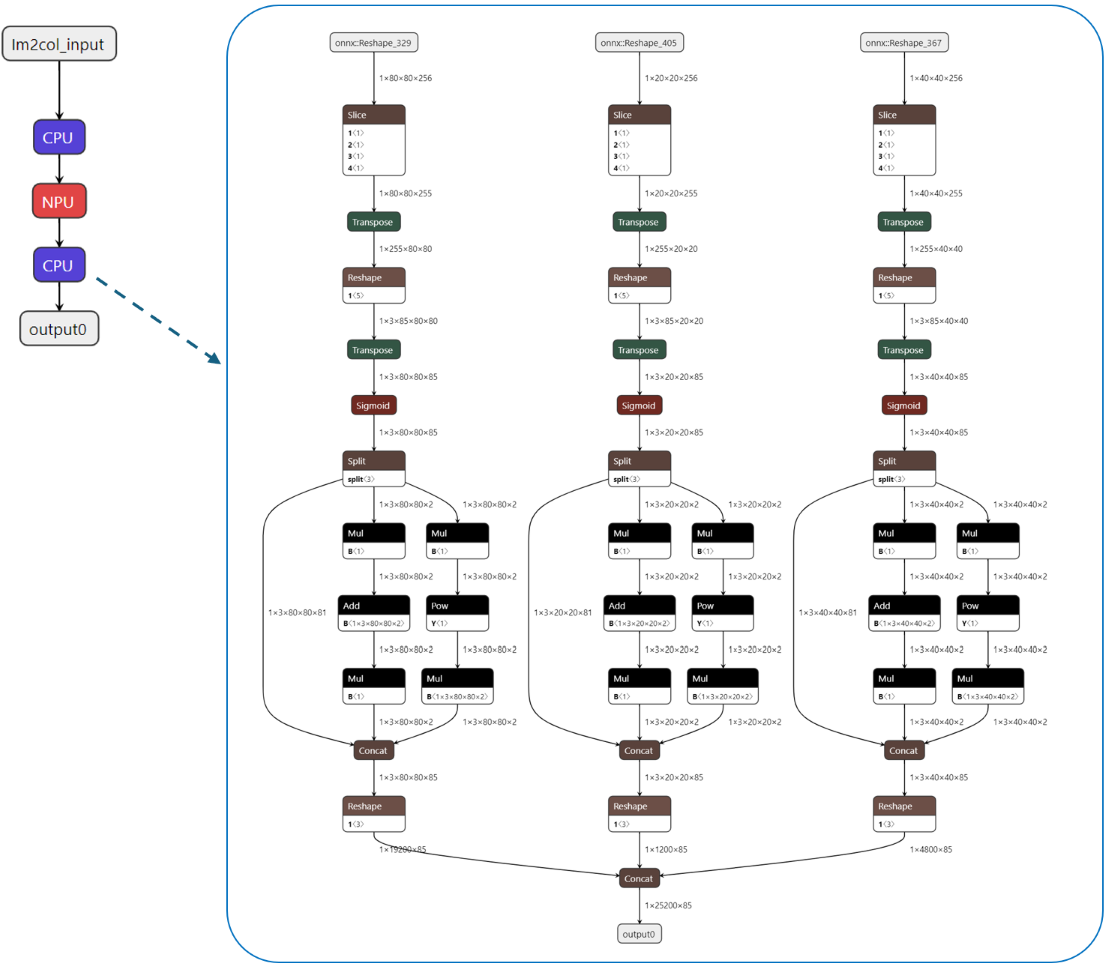

In [9]:
ie_output = ie.run([image_input]) # 추론 수행

num_anchors = 3
anchors = [
    np.array([[10,13], [16,30], [33,23]]),   
    np.array([[116,90], [156,198], [373,326]]),
    np.array([[30,61], [62,45], [59,119]])  
]
feature_shapes = [(80,80), (20,20), (40,40)]  # 각 scale feature map 크기
strides = [8, 32, 16]

# Onnx Runtime 미 사용시 PostProcessing 직접 수행
if io.get_use_ort()==False:

    ## Slice
    ie_output_sliced = [out[..., :255].astype(np.float32) for out in ie_output] # 마지막 한 바이트 Slice
    
    outputs = ie_output_sliced
    batch = ie_output[0].shape[0]
    processed = []

    for idx, output in enumerate(outputs):
        h, w = output.shape[1], output.shape[2]
        stride = np.float32(strides[idx])
        anchor = anchors[idx].astype(np.float32)
        num_anchors = anchor.shape[0]

        ## Tranpose + Reshape + Tranpose
        output = output.astype(np.float32).reshape(batch, h, w, num_anchors, 80 + 5)

        ## Sigmoid
        output = sigmoid_np(output)
        
        ## Split ...
        grid_x, grid_y = np.meshgrid(np.arange(w, dtype=np.float32),
                                     np.arange(h, dtype=np.float32))
        grid = np.stack((grid_x, grid_y), axis=-1)

        xy = ((output[..., 0:2] * 2.0) - 0.5 + grid[None, ..., None, :]) * stride
        wh = ((output[..., 2:4] * 2.0) ** 2) * anchor[None, None, None, :, :]

        ## Concat
        box = np.concatenate((xy, wh), axis=-1)
        final = np.concatenate((box, output[..., 4:]), axis=-1)

        ## Reshape
        final = final.reshape(batch, -1, 80 + 5)

        processed.append(final)

    ## Concat
    ie_output = np.concatenate(processed, axis=1).astype(np.float32)
else:
    ie_output = ie_output[0]


## 5. 후처리 과정

NPU 추론 결과를 실제 검출 결과로 변환하는 과정입니다.

- **디코딩**: 25200개 예측 박스에서 좌표, 신뢰도, 클래스 정보 추출
- **필터링**: 신뢰도 임계값(0.4) 기반 초기 필터링
- **NMS 적용**: IoU 임계값(0.4)으로 중복 박스 제거
- **좌표 변환**: 모델 좌표를 원본 이미지 좌표로 변환

### COCO 데이터셋 클래스 정의

YOLOv5는 **COCO dataset**(Common Objects in Context)으로 학습되어 있으며,  
총 **80개의 객체(object class)** 를 탐지할 수 있습니다.

| **Class 예시** | **설명** |
|:----------------|:-----------|
| `person`, `bicycle`, `car`, `motorcycle`, `bus`, `truck` | 사람 및 탈것 |
| `cat`, `dog`, `horse`, `cow`, `elephant` | 동물 |
| `chair`, `couch`, `bed`, `dining table` | 가구 |
| `tv`, `laptop`, `cell phone`, `microwave`, `oven`, `refrigerator` | 전자기기 |
| `book`, `clock`, `vase`, `scissors`, `teddy bear`, `toothbrush` | 일상 용품 |

In [10]:
classes = [ # COCO dataset class names
    "person", "bicycle", "car", "motorcycle", "airplane", "bus", "train", "truck",
    "boat", "traffic light", "fire hydrant", "stop sign", "parking meter", "bench",
    "bird", "cat", "dog", "horse", "sheep", "cow", "elephant", "bear", "zebra",
    "giraffe", "backpack", "umbrella", "handbag", "tie", "suitcase", "frisbee",
    "skis", "snowboard", "sports ball", "kite", "baseball bat", "baseball glove",
    "skateboard", "surfboard", "tennis racket", "bottle", "wine glass", "cup",
    "fork", "knife", "spoon", "bowl", "banana", "apple", "sandwich", "orange",
    "broccoli", "carrot", "hot dog", "pizza", "donut", "cake", "chair", "couch",
    "potted plant", "bed", "dining table", "toilet", "tv", "laptop", "mouse",
    "remote", "keyboard", "cell phone", "microwave", "oven", "toaster", "sink",
    "refrigerator", "book", "clock", "vase", "scissors", "teddy bear", "hair drier",
    "toothbrush"
]
n_classes = len(classes)

### 모델 출력 디코딩

YOLOv5 출력 텐서 [1, 25200, 85]를 개별 검출 박스 정보로 변환합니다.

---

#### Feature 85 float의 구성

YOLOv5s의 한 detection 벡터는 85개의 float으로 구성되어 있습니다.  
이 중 앞의 5개는 box 정보와 objectness, 나머지 80개는 클래스별 확률 값입니다.

| **Index** | **Field** | **개수** | **설명** | **dtype** |
|:----------:|:-----------|:--------:|:-----------|:-----------|
| **0** | `cx` | 1 | 예측된 바운딩 박스 중심의 x 좌표 (픽셀 단위 또는 정규화) | `float32` |
| **1** | `cy` | 1 | 예측된 바운딩 박스 중심의 y 좌표 | `float32` |
| **2** | `w` | 1 | 예측된 바운딩 박스의 너비 | `float32` |
| **3** | `h` | 1 | 예측된 바운딩 박스의 높이 | `float32` |
| **4** | `objectness` | 1 | 해당 grid cell에 물체가 존재할 확률 | `float32` |
| **5 ~ 84** | `class probabilities` | 80 | COCO dataset 기준 80개 클래스의 확률 값 | `float32 × 80` |

---

In [11]:
# --------------------------------------------------------
# YOLOv5s Output: (1, 25200, 85)
# 85 = [x, y, w, h, obj_conf, 80 class_conf]
# --------------------------------------------------------

ie_output0 = ie_output[0]   # (25200, 85)
num_det = ie_output0.shape[0]
decoded_tensor = []

for i in range(num_det):
    cx, cy, w, h = ie_output0[i, 0:4]
    obj_conf = ie_output0[i, 4]
    class_confs = ie_output0[i, 5:]

    # 가장 높은 클래스 선택
    class_id = np.argmax(class_confs)
    class_score = class_confs[class_id]
    score = obj_conf * class_score

    decoded_tensor.append([cx, cy, w, h, score, class_id])

if len(decoded_tensor) == 0:
    decoded_tensor = np.zeros((1, 6), dtype=float)
else:
    decoded_tensor = np.stack(decoded_tensor)

print("Decoded Tensor Shape:", decoded_tensor.shape)

Decoded Tensor Shape: (25200, 6)


### 필터링

bbox 좌표 변환: 모델 출력은 (cx, cy, w, h) 형태인데, Bounding Box를 그리기 위해선 좌상단 좌표와 우하단 좌표로 변환이 필요합니다.

threshold filtering: 설정한 score_threshold보다 낮은 detection 후보를 제거합니다.

#### *score_threshold 값을 조정하며 image에 box 변화를 확인 가능*

정렬: confidence 높은 순으로 detection 정렬 → NMS 전에 확률 높은 박스부터 확인할 수 있도록 합니다.

### 출력 Output Shape

(N, 6) => N은 Threshold를 통과한 box의 개수입니다.


In [12]:
x = np.squeeze(decoded_tensor)
score_threshold = 0.4 # score 가 0.5 이상인 박스만 존재하도록
iou_threshold = 0.4 # NMS IoU 임계값
colors = np.random.randint(0, 256, [n_classes, 3], np.uint8).tolist() # 클래스별 박스 색상 설정

if x.ndim <= 1 or len(x) == 0:
    print("No detections")


else:
    box = ops.xywh2xyxy(x[..., :4])  # (cx,cy,w,h) → (x1,y1,x2,y2) 좌표 변환
    conf = x[:, 4:5]                 # confidence
    j = x[:, 5:6]                    # class

    mask = conf.flatten() > score_threshold
    filtered = np.concatenate((box, conf, j), axis=1)[mask]

    # confidence 내림차순 정렬
    sorted_indices = np.argsort(-filtered[:, 4])
    x = filtered[sorted_indices]

    print("Shape (box_num, dim):", x.shape)

Shape (box_num, dim): (82, 6)


### NMS (Non-Maximum Suppression) 적용

중복되는 검출 박스를 제거하고 최적의 검출 결과만 유지합니다.

#### **IoU(Intersection over Union) 계산**

- 두 박스가 얼마나 겹치는지 측정하는 값.
- 수식: IoU = 교집합 넓이 / 합집합 넓이

**(1) confidence가 가장 높은 박스 선택**

**(2) 겹치는 박스 제거**
- 선택된 박스와 다른 박스들의 IoU 계산.
- IoU > iou_threshold 인 박스는 같은 물체로 간주하고 제거

**(3) 반복 수행**
- 남은 박스 중에서 다시 confidence 높은 박스를 선택.
- IoU 비교 후 중복 제거, 더 이상 겹치는 박스가 없을 때까지 반복.

#### **NMS 적용 전**
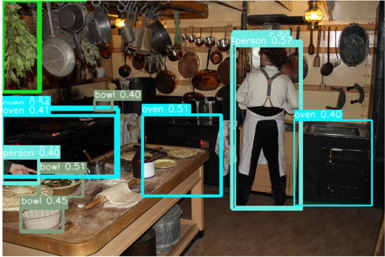

#### **NMS 적용 후**

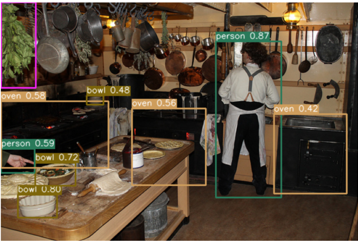


In [13]:
    if len(x) > 0:
        x1, y1, x2, y2, scores, labels = (
            x[:, 0], x[:, 1], x[:, 2], x[:, 3], x[:, 4], x[:, 5]
        )
        keep = []
        idxs = scores.argsort()[::-1]  # 높은 confidence부터 정렬
        while len(idxs) > 0:
            i = idxs[0]
            keep.append(i)
            xx1 = np.maximum(x1[i], x1[idxs[1:]])
            yy1 = np.maximum(y1[i], y1[idxs[1:]])
            xx2 = np.minimum(x2[i], x2[idxs[1:]])
            yy2 = np.minimum(y2[i], y2[idxs[1:]])

            w = np.maximum(0.0, xx2 - xx1)
            h = np.maximum(0.0, yy2 - yy1)
            inter = w * h
            union = ((x2[i]-x1[i]) * (y2[i]-y1[i]) +
                    (x2[idxs[1:]]-x1[idxs[1:]]) * (y2[idxs[1:]]-y1[idxs[1:]]) - inter)
            iou = inter / (union + 1e-6)

            idxs = idxs[1:][iou <= iou_threshold]
        x = x[keep]
    print("Shape After NMS:", x.shape)

Shape After NMS: (9, 6)


### 좌표 변환 (모델 좌표 → 원본 이미지 좌표)

- 전처리 과정에서 입력 이미지를 모델 크기(예: 640x640)에 맞췄기 때문에 원본 이미지 크기에 맞게 좌표를 변환합니다.

#### Box 보정 방식
- pad(좌우/상하 여백 크기)와 ratio(resize 배율)를 이용해 **원래 좌표계로 복구** 합니다.  
- 변환 과정은 padding을 빼주고 resize 배율로 나누어 원본 크기에 맞추는 방식.  

In [14]:
    h, w = frame.shape[:2]
    x1 = np.clip(((x[:, 0] - pad[0]) / ratio[0]).astype(int), 0, w - 1)
    y1 = np.clip(((x[:, 1] - pad[1]) / ratio[1]).astype(int), 0, h - 1)
    x2 = np.clip(((x[:, 2] - pad[0]) / ratio[0]).astype(int), 0, w - 1)
    y2 = np.clip(((x[:, 3] - pad[1]) / ratio[1]).astype(int), 0, h - 1)
    x[:, 0:4] = np.stack([x1, y1, x2, y2], axis=1)

    for i, (x1, y1, x2, y2, score, label) in enumerate(x):
        print(f"Box {i+1}: ({int(x1)}, {int(y1)}) - ({int(x2)}, {int(y2)}), "
              f"score={score:.2f}, class={int(label)}")

Box 1: (384, 70) - (501, 349), score=0.87, class=0
Box 2: (30, 344) - (100, 385), score=0.80, class=45
Box 3: (61, 287) - (133, 328), score=0.72, class=45
Box 4: (0, 0) - (62, 153), score=0.71, class=58
Box 5: (0, 262) - (60, 305), score=0.59, class=0
Box 6: (0, 177) - (192, 296), score=0.58, class=69
Box 7: (234, 190) - (366, 327), score=0.56, class=69
Box 8: (153, 167) - (183, 183), score=0.48, class=45
Box 9: (488, 200) - (618, 342), score=0.42, class=69


## 6. 결과 시각화

최종 검출 결과를 시각화하고 이미지로 저장합니다.

### 검출 결과 시각화

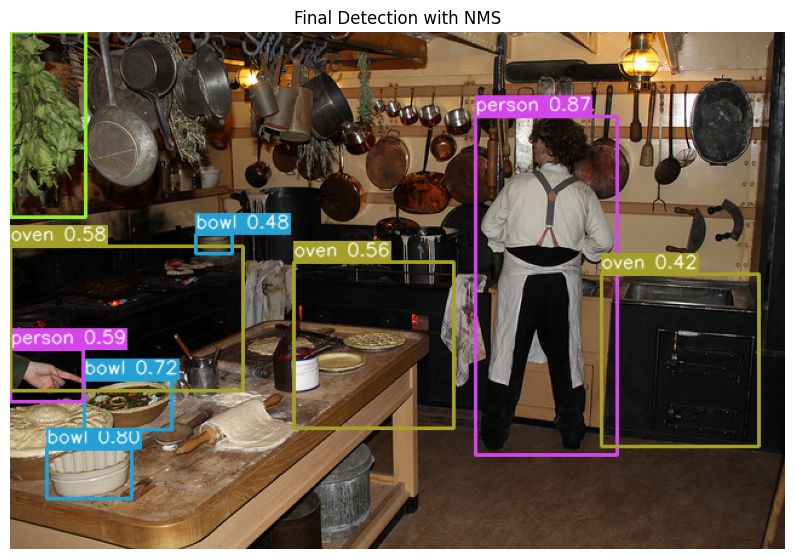

[DXRT_IPC][Error] [IPCMessageQueueLinux] msgrcv 1 failed43
[DXRT_IPC][Error] ReceiveFromServer fail, errno = 43


In [15]:
    img_vis = frame.copy()
    for r in x:
        x1, y1, x2, y2, conf, label = r
        label = int(label)
        cls_name = classes[label]
        color = colors[label]

        pt1, pt2 = (int(x1), int(y1)), (int(x2), int(y2))
        cv2.rectangle(img_vis, pt1, pt2, color, 2)

        text = f"{cls_name} {conf:.2f}"
        (tw, th), baseline = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, 0.5, 1)
        cv2.rectangle(img_vis, (pt1[0], pt1[1] - th - baseline),
                      (pt1[0] + tw, pt1[1]), color, -1)
        cv2.putText(img_vis, text, (pt1[0], pt1[1] - baseline),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255,255,255), 1, cv2.LINE_AA)

    show_img(img_vis, "Final Detection with NMS")